We will analyze a reconstruction error on the mnist dataset

In [87]:
import numpy as np
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as  plt
from sklearn.model_selection import train_test_split

In [88]:
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)
y = y.astype(int)
X = X / 255.0

### Image Reduction and Reconstruction using Random Projection

In [106]:
m = X.shape[1]
k = 800
P = np.random.normal(loc=0, scale=1/np.sqrt(k), size=(m, k))

print(f"Original dimension (m): {m}")
print(f"Target dimension (k): {k}")
print(f"Random Projection Matrix shape: {P.shape}")

Original dimension (m): 784
Target dimension (k): 800
Random Projection Matrix shape: (784, 800)


In [107]:
X_random_projected = X @ P

print(f"Randomly Projected data shape: {X_random_projected.shape}")

Randomly Projected data shape: (70000, 800)


In [108]:
P_t = np.transpose(P)
X_random_reconstructed = X_random_projected @ P_t

print(f"Randomly Reconstructed data shape: {X_random_reconstructed.shape}")

Randomly Reconstructed data shape: (70000, 784)


### Calculate Reconstruction Error for Random Projection

In [109]:
random_reconstruction_error = np.mean(np.square(X - X_random_reconstructed))

print(f"Mean Squared Reconstruction Error (Random Projection): {random_reconstruction_error:.4f}")

Mean Squared Reconstruction Error (Random Projection): 0.1118


In [94]:
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size, size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        r_images = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(r_images, axis=1))
    image = np.concatenate(row_images, axis=0)
    plt.imshow(image, cmap='binary', **options)
    plt.axis('off')

### Visualize Original vs. Randomly Reconstructed Images

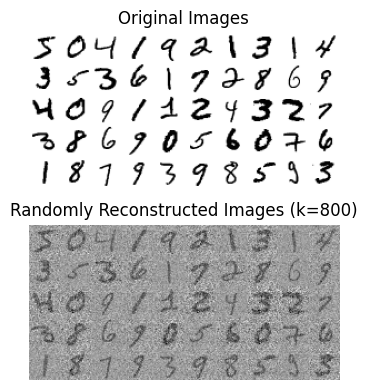

In [110]:
plt.figure(figsize=(10, 4))

plt.subplot(2, 1, 1)
plt.title('Original Images')
plot_digits(X[:50], images_per_row=10)

plt.subplot(2, 1, 2)
plt.title(f'Randomly Reconstructed Images (k={k})')
plot_digits(X_random_reconstructed[:50], images_per_row=10)

plt.tight_layout()
plt.show()

### Splitting Data into Training and Test Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

k = 350
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (56000, 784)
X_test shape: (14000, 784)


In [101]:
m = X_train.shape[1]
k = 350
P = np.random.normal(loc=0, scale=1/np.sqrt(k), size=(m, k))

print(f"Original dimension (m): {m}")
print(f"Target dimension (k): {k}")
print(f"Random Projection Matrix shape: {P.shape}")

Original dimension (m): 784
Target dimension (k): 350
Random Projection Matrix shape: (784, 350)


In [102]:
X_random_projected = X_test @ P

print(f"Randomly Projected data shape: {X_random_projected.shape}")

Randomly Projected data shape: (14000, 350)


### Calculate Reconstruction Error on Test Set

In [103]:
P_t = np.transpose(P)
X_random_reconstructed = X_random_projected @ P_t

print(f"Randomly Reconstructed data shape: {X_random_reconstructed.shape}")

Randomly Reconstructed data shape: (14000, 784)


In [104]:
test_reconstruction_error = np.mean(np.square(X_test - X_test_reconstructed))

print(f"Mean Squared Reconstruction Error on Test Set: {test_reconstruction_error:.4f}")

Mean Squared Reconstruction Error on Test Set: 0.0129


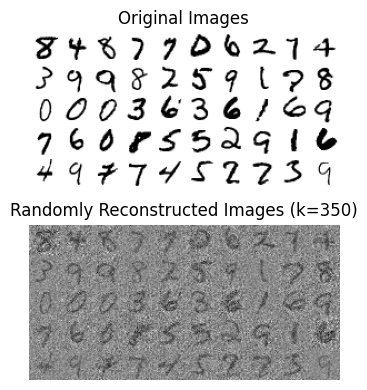

In [105]:
plt.figure(figsize=(10, 4))

plt.subplot(2, 1, 1)
plt.title('Original Images')
plot_digits(X_test[:50], images_per_row=10)

plt.subplot(2, 1, 2)
plt.title(f'Randomly Reconstructed Images (k={k})')
plot_digits(X_random_reconstructed[:50], images_per_row=10)

plt.tight_layout()
plt.show()